# How much of the neural variability does LD1 explain?

Every neuromodulator fiber with ≥ 5 sessions (VTA-DA, SNc-DA, DR-5HT, LC-NE, NBM-ACh). Per fiber-session, the mean
photometry traces around the stimulus (all trials), correct feedback and error feedback, concatenated (`ld1_neural.
NEURAL_KEYS`); as a positive control, the movement traces around the stimulus (wheel speed, whisker ME).

**The statistic** (`ld1_neural.explained`): the share of the trace variance (summed over time samples) explained by a
predictor with a **separate slope per group**, after removing each group's mean trace, against a null that permutes
the predictor within group. Separate slopes because the neuromodulators respond to LD1 in different directions
(VTA up, NE down) and a common slope would cancel them. Two levels:
- **across mice**: one mean trace per mouse (sessions → fibers → mouse); groups = neuromodulator target, so the
  question is variability *between mice of the same type*;
- **within mice**: one trace per fiber-session; groups = fibers, so session-to-session variability.

Read the **excess over the null**, not the raw share: with few units per group a slope always explains something
(across mice, 3–7 mice per target, chance is already ≈ 30 %). `unique_explained` gives LD1's share beyond RT and
accuracy (and quiescence wheel speed). Caveats: bilateral NBM fibers count as separate fibers here; the photometry is
the export's session z-score.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nm_projection as npj
import ld1_neural as L

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
TARGETS = ['VTA-DA', 'SNc-DA', 'DR-5HT', 'LC-NE', 'NBM-ACh']
emb, sc = npj.frame()
A = npj.project(emb, sc, protocol=None)
T = pd.concat([L.session_table(A, targets=(t,)) for t in TARGETS], ignore_index=True)
T = T.join(A.loc[A['group'] == 'NM', ['LD10']], on='eid')
TR = L.traces(sorted(T['eid'].unique()))
PRED = ['LD1', 'LD2', 'LD3', 'LD10', 'log_reaction', 'correct']
T.groupby('target_NM').agg(mice=('subject', 'nunique'), fibers=('fiber', 'nunique'), sessions=('eid', 'size'))

,mice,fibers,sessions
target_NM,,,
DR-5HT,7,7,133
LC-NE,3,3,83
NBM-ACh,4,6,63
SNc-DA,5,5,63
VTA-DA,5,5,135


In [2]:
#%%
""" 1. SHARE EXPLAINED PER PREDICTOR, across mice and within mice, neural and movement traces """
rows, CURVES = [], {}
for level in ['mouse', 'session']:
    for kind, keys in [('neural', L.NEURAL_KEYS), ('movement', L.MOVEMENT_KEYS)]:
        Y, m = L.trace_matrix(T, TR, keys, level=level, predictors=tuple(PRED + ['wheel_speed_Quiescence']))
        g = m['target_NM'] if level == 'mouse' else m['fiber']
        for p in PRED:
            r = L.explained(Y, m[p].to_numpy(), g, n_perm=2000)
            rows.append(dict(level=level, traces=kind, predictor=p, units=len(Y), share=r['share'],
                             null=r['null_mean'], excess=r['share'] - r['null_mean'], p=r['p']))
            CURVES[(level, kind, p)] = r['curve']
SHARE = pd.DataFrame(rows)
SHARE.pivot_table(index='predictor', columns=['level', 'traces'], values=['excess', 'p'], sort=False).round(3)

excess                                p                          
level         mouse          session           mouse          session         
traces       neural movement  neural movement neural movement  neural movement
predictor                                                                     
LD1           0.091    0.066   0.115    0.168  0.074    0.218   0.000    0.000
LD2           0.152    0.306   0.104    0.125  0.010    0.003   0.000    0.000
LD3          -0.007    0.011   0.033    0.100  0.528    0.399   0.005    0.000
LD10          0.060    0.174   0.033    0.028  0.170    0.047   0.006    0.026
log_reaction  0.003    0.184   0.143    0.234  0.468    0.027   0.000    0.000
correct       0.091   -0.012   0.065    0.079  0.070    0.496   0.000    0.000

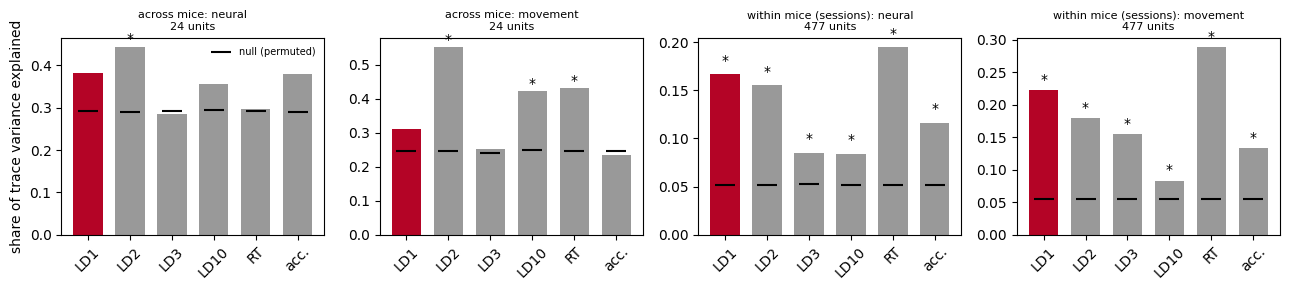

In [3]:
#%%
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=False)
for ax, (level, kind) in zip(axes, [('mouse', 'neural'), ('mouse', 'movement'), ('session', 'neural'), ('session', 'movement')]):
    d = SHARE[(SHARE['level'] == level) & (SHARE['traces'] == kind)].set_index('predictor').reindex(PRED)
    x = np.arange(len(d))
    ax.bar(x, d['share'], color=['#b40426' if p == 'LD1' else '0.6' for p in d.index], width=0.7)
    ax.scatter(x, d['null'], marker='_', s=200, color='k', zorder=3, label='null (permuted)')
    for xi, (s_, p_) in enumerate(zip(d['share'], d['p'])):
        ax.text(xi, s_ + 0.01, '*' if p_ < 0.05 else '', ha='center')
    ax.set_xticks(x); ax.set_xticklabels([p.replace('log_reaction', 'RT').replace('correct', 'acc.') for p in d.index], rotation=45)
    ax.set_title(f"{'across mice' if level == 'mouse' else 'within mice (sessions)'}: {kind}\n{int(d['units'].iloc[0])} units",
                 fontsize=8)
axes[0].set_ylabel('share of trace variance explained'); axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

In [4]:
#%%
""" 2. WITHIN MICE, PER TARGET: LD1's total share, and its unique share beyond RT + accuracy """
out = {}
for kind, keys in [('neural', L.NEURAL_KEYS), ('movement', L.MOVEMENT_KEYS)]:
    Y, m = L.trace_matrix(T, TR, keys, level='session', predictors=('LD1', 'log_reaction', 'correct', 'wheel_speed_Quiescence'))
    for tg, g in m.groupby('target_NM'):
        i = g.index.to_numpy()
        r = L.explained(Y[i], g['LD1'].to_numpy(), g['fiber'], n_perm=2000)
        u = L.unique_explained(Y[i], g[['log_reaction', 'correct']].to_numpy(), g['LD1'].to_numpy(), g['fiber'], n_perm=1000)
        out[(kind, tg)] = dict(sessions=len(i), share=r['share'], null=r['null_mean'], p=r['p'],
                               unique=u['share'], unique_null=u['null_mean'], p_unique=u['p'])
    u = L.unique_explained(Y, m[['log_reaction', 'correct', 'wheel_speed_Quiescence']].to_numpy(), m['LD1'].to_numpy(),
                           m['fiber'], n_perm=1000)
    print(f"{kind}: LD1 unique beyond RT + accuracy + quiescence wheel, all fibers: {u['share']:.3f} (null {u['null_mean']:.3f}, p {u['p']:.3f})")
PER = pd.DataFrame(out).T
PER.round(3)

neural: LD1 unique beyond RT + accuracy + quiescence wheel, all fibers: 0.063 (null 0.013, p 0.001)


movement: LD1 unique beyond RT + accuracy + quiescence wheel, all fibers: 0.034 (null 0.006, p 0.003)


sessions  share   null      p  unique  unique_null  p_unique
neural   DR-5HT      133.0  0.111  0.055  0.007   0.083        0.048     0.021
         LC-NE        83.0  0.175  0.040  0.000   0.136        0.036     0.003
         NBM-ACh      63.0  0.174  0.094  0.011   0.138        0.082     0.026
         SNc-DA       63.0  0.153  0.084  0.040   0.081        0.058     0.128
         VTA-DA      135.0  0.198  0.042  0.000   0.069        0.035     0.002
movement DR-5HT      133.0  0.150  0.077  0.005   0.096        0.055     0.023
         LC-NE        83.0  0.097  0.033  0.030   0.020        0.025     0.454
         NBM-ACh      63.0  0.270  0.098  0.007   0.120        0.056     0.007
         SNc-DA       63.0  0.160  0.074  0.016   0.065        0.056     0.276
         VTA-DA      135.0  0.303  0.037  0.000   0.085        0.024     0.002

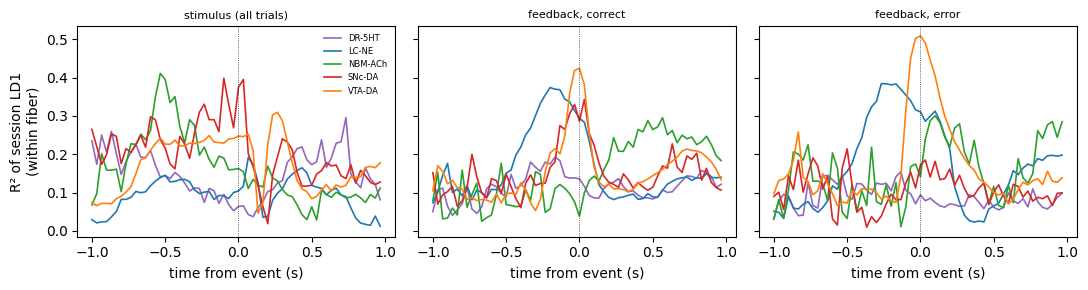

In [5]:
#%%
""" 3. WHERE IN THE TRACE: within mice, per-sample R² of LD1 (per-fiber slopes), per target """
Y, m = L.trace_matrix(T, TR, L.NEURAL_KEYS, level='session', predictors=('LD1',))
nT = len(next(iter(TR.values()))['time'])
t = next(iter(TR.values()))['time']
COL = {'SNc-DA': '#d62728', 'VTA-DA': '#ff7f0e', 'DR-5HT': '#9467bd', 'LC-NE': '#1f77b4', 'NBM-ACh': '#2ca02c'}
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for tg, g in m.groupby('target_NM'):
    i = g.index.to_numpy()
    r = L.explained(Y[i], g['LD1'].to_numpy(), g['fiber'], n_perm=200)
    for k, ax in enumerate(axes):
        ax.plot(t, r['curve'][k * nT:(k + 1) * nT], color=COL[tg], lw=1.2, label=tg)
for ax, ttl in zip(axes, ['stimulus (all trials)', 'feedback, correct', 'feedback, error']):
    ax.axvline(0, color='k', lw=0.5, ls=':'); ax.set_title(ttl, fontsize=8); ax.set_xlabel('time from event (s)')
axes[0].set_ylabel('R² of session LD1\n(within fiber)'); axes[0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

## Reading

- **Across mice the question cannot be answered with these cohorts.** With 3–7 mice per neuromodulator a per-target
  slope already explains ≈ 30 % by chance; LD1's excess is +9 points (p = 0.07) and, tellingly, LD1 does not even
  explain the mice's *movement* traces above chance (p = 0.22; RT and LD2 do). Between-mouse differences in the traces
  are dominated by what each fiber picks up (placement, expression), and 24 mice in five groups are too few to see
  LD1 through that.
- **Within mice, LD1 explains a real slice of session-to-session neural variability**: 17 % of the trace variance
  against 5 % by chance (excess +12 points), about as much as RT (+14) and more than LD3 or the control axis LD10
  (+3). **Beyond RT and accuracy, LD1 still adds 10 % (null 4 %), and 6 % (null 1 %) beyond quiescence wheel speed
  too** — so it carries session state that RT, accuracy and quiescent movement do not.
- **Per neuromodulator** (within mice, LD1's unique share beyond RT + accuracy vs its null): LC-NE 13.6 vs 3.6 %
  (p = 0.003), VTA-DA 6.9 vs 3.5 % (p = 0.002), NBM-ACh 13.8 vs 8.2 % (p = 0.03; bilateral fibers counted separately,
  so optimistic), DR-5HT 8.3 vs 4.8 % (p = 0.02), SNc-DA n.s. Largest for NE, where the per-measure analysis
  (`7_ne_ld1_within_mouse`) found smaller transients at high LD1.
- **Where in the trace** (section 3): the R² curves show the time windows that carry it per neuromodulator.

In short: LD1 is a useful description of *session state* for the neural signals (it explains a few percent of trace
variance beyond the obvious behavioural covariates, for every neuromodulator except SNc); whether it describes
*mouse identity* in the neural signals needs many more mice per neuromodulator than this dataset has.